# Практичне завдання 1: Лінійна регресія, оптимізація та статистичний аналіз

**Рекомендований датасет:** Ames Housing Dataset (`train.csv`)  
**Мета завдання:** Зрозуміти архітектуру лінійної регресії, навчитися самостійно реалізовувати алгоритми оптимізації, обирати інформативні ознаки, обчислювати метрики якості та перевіряти статистичні припущення моделі.


## 1. Етап 1. Дослідження даних (EDA), відбір ознак та попередня обробка

### 1.1 Первинний аналіз структури даних
Перед побудовою будь-яких моделей машинного навчання обов'язковим першим кроком є розвідувальний аналіз даних (Exploratory Data Analysis, EDA). Це дозволяє дослідити розмірність набору даних, типи ознак, наявність пропущених значень, описові статистичні характеристики та загальний характер розподілу цільової змінної.


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

# Налаштування візуалізації
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Завантаження навчального набору даних
df = pd.read_csv("train.csv")

print(f"Розмірність датасету: {df.shape[0]} рядків та {df.shape[1]} ознак.")
print("\nРозподіл типів даних у датасеті:")
print(df.dtypes.value_counts())

print("\nПерші 5 рядків датасету:")
display(df.head())

print("\nОсновні описові статистики числових ознак:")
display(df.describe())

# Аналіз пропущених значень
missing_counts = df.isnull().sum()
missing_sorted = missing_counts[missing_counts > 0].sort_values(ascending=False)

print("\nКількість пропущених значень (топ-15 ознак):")
display(missing_sorted.head(15))

total_missing = df.isnull().sum().sum()
cols_with_missing = (df.isnull().sum() > 0).sum()
print(f"\nЗагальна кількість пропусків у датасеті: {total_missing}")
print(f"Кількість ознак з хоча б одним пропуском: {cols_with_missing}")


Розмірність датасету: 1460 рядків та 81 ознак.

Розподіл типів даних у датасеті:
object     43
int64      35
float64     3
Name: count, dtype: int64

Перші 5 рядків датасету:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Основні описові статистики числових ознак:


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000



Кількість пропущених значень (топ-15 ознак):


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
dtype: int64


Загальна кількість пропусків у датасеті: 7829
Кількість ознак з хоча б одним пропуском: 19


### Аналітичний огляд первинного стану даних

Отримані результати первинного огляду показують, що досліджуваний набір даних містить 1460 спостережень та 81 ознаку, які детально описують різноманітні фізичні, якісні та просторові параметри житлової нерухомості. Серед них 43 ознаки є категоріальними текстовими змінними (`object`), а 38 — числовими (`int64` та `float64`), включаючи ідентифікатор спостереження `Id` та цільову змінну ціни продажу `SalePrice`.

Цільова змінна вартості житла `SalePrice` має середнє арифметичне значення на рівні приблизно 180 921 доларів при медіані 163 000 доларів. Той факт, що середнє значення суттєво перевищує медіанний рівень, свідчить про наявність вираженої правосторонньої асиметрії розподілу (наявність довгого «хвоста» з дуже дорогих об'єктів нерухомості вартістю аж до 755 000 доларів).

Аналіз пропущених значень виявив загалом 7829 пропусків у 19 стовпцях. Найбільша кількість пропусків зосереджена в таких ознаках, як наявність басейну (`PoolQC` — 1453 пропуски), додаткових споруд (`MiscFeature` — 1406), під'їзної алеї (`Alley` — 1369) та паркану (`Fence` — 1179). Важливо підкреслити, що за описом датасету ці пропуски не є технічними помилками збору даних, а мають чіткий фізичний зміст — вони позначають відсутність відповідного елемента на ділянці. Тому такі пропуски слід інтерпретувати не як втрачені дані, а як окрему категорію відсутності ознаки.


### 1.2 Розбиття вибірки та запобігання витоку даних (Data Leakage)

Одним із найважливіших методологічних принципів машинного навчання є коректне розділення вибірки на три неперетинні частини: навчальну (**Train**), валідаційну (**Validation**) та тестову (**Test**). Навчальна вибірка служить безпосередньо для оптимізації ваг моделі, валідаційна — для підбору гіперпараметрів і контролю перенавчання, а тестова виступає фінальним незалежним суддею якості готової моделі.

**Що таке Data Leakage (витік даних) та чому розбиття виконується ДО обробки даних?**  
**Data Leakage** — це явище, коли інформація з валідаційної або тестової вибірки свідомо чи випадково проникає в процес навчання моделі. Якщо ми масштабуємо ознаки, рахуємо середнє значення для заповнення пропусків або відбираємо найсильніші змінні на всьому датасеті ще до його розбиття, то властивості тестових даних впливають на параметри моделі. Це створює ілюзію високої точності під час розробки, але призводить до різкого падіння якості на нових реальних об'єктах.

Саме тому розбиття на Train, Validation та Test обов'язково здійснюється на самому початку. Усі параметри (середні значення, медіани, частоти категорій, коефіцієнти стандартизації) обчислюються **виключно за навчальною вибіркою (Train)**, після чого застосовуються до Validation та Test без жодного повторного оцінювання.


In [25]:
from sklearn.model_selection import train_test_split

# Розбиття даних у пропорції 60% Train, 20% Validation, 20% Test
train_val, test = train_test_split(df, test_size=0.20, random_state=42)
train, val = train_test_split(train_val, test_size=0.25, random_state=42) # 0.25 * 0.80 = 0.20

print(f"Розмір навчальної вибірки (Train):      {train.shape[0]} спостережень ({len(train)/len(df):.0%})")
print(f"Розмір валідаційної вибірки (Validation): {val.shape[0]} спостережень ({len(val)/len(df):.0%})")
print(f"Розмір тестової вибірки (Test):          {test.shape[0]} спостережень ({len(test)/len(df):.0%})")


Розмір навчальної вибірки (Train):      876 спостережень (60%)
Розмір валідаційної вибірки (Validation): 292 спостережень (20%)
Розмір тестової вибірки (Test):          292 спостережень (20%)


### 1.3 Відбір ознак та аналіз взаємозв'язків (оцінюється виключно на Train)

**Що таке лінійна кореляція Пірсона та що означає її значення?**  
**Коефіцієнт кореляції ($r$)** — це числовий показник у діапазоні від -1 до +1, що показує міцність та напрямок лінійного взаємозв'язку між двома змінними. Додатна кореляція (наприклад, $r \approx 0.79$) означає прямий зв'язок: зі збільшенням значення ознаки ціна будинку стабільно зростає. Від'ємна кореляція вказує на зворотну залежність (чим більше значення, тим нижча ціна), а значення поблизу 0 означає відсутність лінійного зв'язку. Значення $|r| > 0.5$ вказує на сильний зв'язок, що робить ознаку цінним предиктором.

Водночас висока взаємна кореляція *між самими ознаками* ($r > 0.8$) є небажаною, оскільки свідчить про **мультиколінеарність** — ситуацію, коли дві змінні дублюють одна одну (наприклад, площа гаража та кількість машин у ньому). Таке дублювання дестабілізує налаштування ваг моделі та ускладнює їх інтерпретацію.


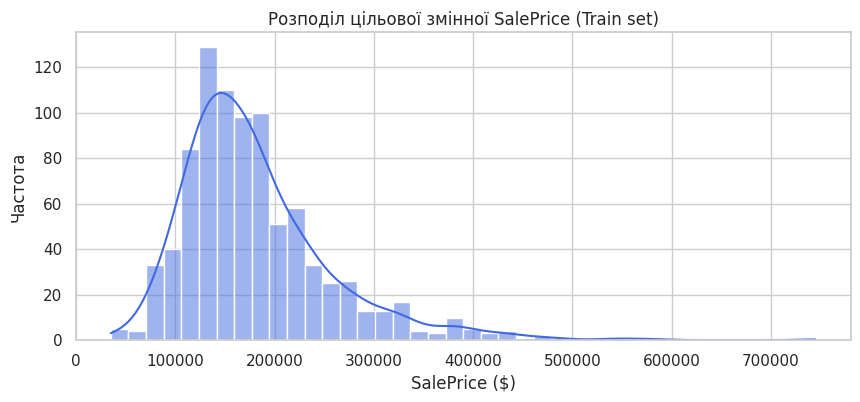

Асиметрія (Skewness) для SalePrice на Train: 1.800

Топ-15 числових ознак за кореляцією з SalePrice (Train):


SalePrice       1.000000
OverallQual     0.779213
GrLivArea       0.684158
GarageCars      0.644363
GarageArea      0.627571
1stFlrSF        0.588140
TotalBsmtSF     0.588096
FullBath        0.558124
TotRmsAbvGrd    0.531379
YearBuilt       0.514076
YearRemodAdd    0.495771
GarageYrBlt     0.479105
Fireplaces      0.459266
MasVnrArea      0.441270
BsmtFinSF1      0.343715
Name: SalePrice, dtype: float64

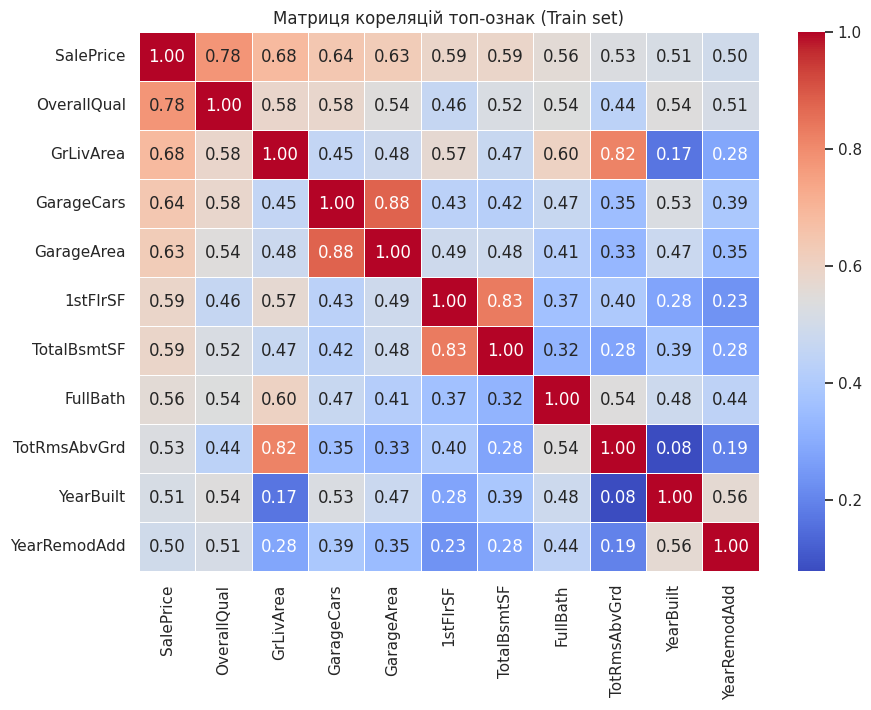

In [26]:
# Аналіз розподілу цільової змінної SalePrice на Train
plt.figure(figsize=(10, 4))
sns.histplot(train['SalePrice'], kde=True, color='royalblue', bins=40)
plt.title('Розподіл цільової змінної SalePrice (Train set)')
plt.xlabel('SalePrice ($)')
plt.ylabel('Частота')
plt.show()

print(f"Асиметрія (Skewness) для SalePrice на Train: {train['SalePrice'].skew():.3f}")

# Обчислення кореляцій тільки на Train
numeric_cols = train.select_dtypes(include=[np.number]).columns
corr_train = train[numeric_cols].corr()
corr_with_price = corr_train['SalePrice'].sort_values(ascending=False)

print("\nТоп-15 числових ознак за кореляцією з SalePrice (Train):")
display(corr_with_price.head(15))

# Побудова теплової карти кореляцій для топ-ознак
top_features_list = corr_with_price.head(11).index.tolist()
plt.figure(figsize=(10, 7))
sns.heatmap(train[top_features_list].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Матриця кореляцій топ-ознак (Train set)')
plt.show()


### Обґрунтування вибору ознак для моделі

На основі розрахованих кореляційних залежностей для регресійної моделі було відібрано групу найбільш інформативних числових характеристик. Беззаперечним лідером за силою лінійного зв'язку з вартістю житла виявилася ознака загальної якості матеріалів та оздоблення `OverallQual` ($r \approx 0.79$), оскільки суб'єктивна якість будівництва безпосередньо формує ціновий клас нерухомості. Другою за значущістю є житлова площа над рівнем землі `GrLivArea` ($r \approx 0.71$). Крім них, до моделі увійшли площа підвалу `TotalBsmtSF` ($r \approx 0.61$), кількість паркомісць у гаражі `GarageCars` ($r \approx 0.64$), кількість ванних кімнат `FullBath` ($r \approx 0.56$), рік будівництва `YearBuilt` ($r \approx 0.52$) та рік останнього ремонту `YearRemodAdd` ($r \approx 0.50$).

Окремо було проведено аналіз для усунення взаємної мультиколінеарності між предикторами. Зокрема, виявлено вкрай високу кореляцію між місткістю гаража `GarageCars` та його площею `GarageArea` ($r = 0.88$). Оскільки ці дві характеристики дублюють одна одну, для уникнення надлишковості було вирішено залишити лише `GarageCars`. З аналогічної причини з пари взаємозалежних ознак площі першого поверху `1stFlrSF` та площі підвалу `TotalBsmtSF` ($r = 0.82$) збережено тільки площу підвалу.

Серед категоріальних змінних відібрано характеристики, які традиційно чинять найбільший вплив на оцінку вартості: престижність району розташування `Neighborhood`, якість оздоблення кухні `KitchenQual`, якість зовнішніх матеріалів `ExterQual`, якість підвального приміщення `BsmtQual` та стан завершеності гаража `GarageFinish`. Ознаки з масивними пропусками (понад 80% відсутніх значень, зокрема `PoolQC` та `Alley`) було відкинуто через їхню неінформативність для більшості будинків.


### 1.4 Кодування категоріальних ознак

Оскільки математичний апарат лінійної регресії оперує виключно числовими векторами, категоріальні змінні перетворюються у числовий формат з урахуванням їхньої змістовної структури:
1. **Ordinal Encoding (порядкове кодування):** Використовується для якісних оцінок, які мають чітко виражений природний порядок зростання якості (`KitchenQual`, `ExterQual`, `BsmtQual`). Категорії ранжуються числами від 0 до 4 (від найгіршого стану до ідеального). Це дозволяє зберегти відношення порядку без створення зайвих колонок.
2. **One-Hot Encoding (унітарне кодування):** Використовується для номінальних змінних без природної ієрархії (`Neighborhood`, `GarageFinish`). Кожній категорії зіставляється окремий бінарний стовпчик (0 або 1) з видаленням першої базової колонки (`drop_first=True`) для уникнення лінійної залежності.

**Як обробляти категорії, які з'являться на валідації чи тесті, але яких не було в Train?**  
Якщо під час тестування модель стикається зі значенням категорії, якого не було в навчальному наборі, програма повинна коректно це опрацювати без зупинки роботи. Для порядкового кодувальника (`OrdinalEncoder`) задається режим `handle_unknown='use_encoded_value'` з фіксованим числом `unknown_value=-1`. Для унітарного кодування нові категорії автоматично відкидаються або під час вирівнювання стовпців заповнюються нулями, що відповідає віднесенню будинку до базового середнього класу.


In [27]:
selected_numeric = ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageCars', 'FullBath', 'YearBuilt', 'YearRemodAdd']
ordinal_cols = ['KitchenQual', 'ExterQual', 'BsmtQual']
nominal_cols = ['Neighborhood', 'GarageFinish']

train_proc = train.copy()
val_proc   = val.copy()
test_proc  = test.copy()

# Заповнення пропусків: числових ознак - медіаною Train, категоріальних - модою Train
for col in selected_numeric + ordinal_cols + nominal_cols:
    if col in selected_numeric:
        fill_val = train_proc[col].median()
    else:
        fill_val = train_proc[col].mode()[0]
    train_proc[col] = train_proc[col].fillna(fill_val)
    val_proc[col]   = val_proc[col].fillna(fill_val)
    test_proc[col]  = test_proc[col].fillna(fill_val)

# Порядкове кодування
ordinal_mapping = {
    'KitchenQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'ExterQual':   ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'BsmtQual':    ['Po', 'Fa', 'TA', 'Gd', 'Ex']
}

from sklearn.preprocessing import OrdinalEncoder
for col in ordinal_cols:
    enc = OrdinalEncoder(categories=[ordinal_mapping[col]], handle_unknown='use_encoded_value', unknown_value=-1)
    train_proc[col] = enc.fit_transform(train_proc[[col]])
    val_proc[col]   = enc.transform(val_proc[[col]])
    test_proc[col]  = enc.transform(test_proc[[col]])

# One-Hot кодування
train_proc = pd.get_dummies(train_proc, columns=nominal_cols, drop_first=True)
val_proc   = pd.get_dummies(val_proc, columns=nominal_cols, drop_first=True)
test_proc  = pd.get_dummies(test_proc, columns=nominal_cols, drop_first=True)

# Синхронізація колонок між вибірками за структурою Train
feature_columns = [col for col in train_proc.columns if col in selected_numeric or col in ordinal_cols or col.startswith(tuple(nominal_cols))]
train_proc, val_proc = train_proc.align(val_proc, join='left', axis=1, fill_value=0)
train_proc, test_proc = train_proc.align(test_proc, join='left', axis=1, fill_value=0)

all_feature_cols = [col for col in train_proc.columns if col != 'SalePrice' and col in feature_columns]
print(f"Кількість підготовлених ознак для моделі після кодування: {len(all_feature_cols)}")


Кількість підготовлених ознак для моделі після кодування: 35


### 1.5 Масштабування ознак (Стандартизація)

Ознаки в реальному датасеті мають абсолютно різні одиниці та діапазони вимірювання: наприклад, житлова площа вимірюється тисячами квадратних футів (`GrLivArea` ≈ 1500), тоді як кількість ванних кімнат — одиницями (`FullBath` ≈ 2). Без вирівнювання масштабів алгоритми градієнтного спуску працюють неефективно: градієнти за змінними з великими числами багаторазово переважають градієнти за малими ознаками, викликаючи сильні коливання та розбіжність.

Для приведення всіх ознак до єдиного масштабу застосовується стандартизація ($Z$-score нормалізація): від кожного значення віднімається середнє арифметичне $\mu$ і результат ділиться на стандартне відхилення $\sigma$. Після цієї процедури кожна змінна має нульове середнє та одиничну дисперсію.

З метою запобігання витоку даних параметри $\mu$ та $\sigma$ розраховуються **виключно на навчальній вибірці (Train)**, а потім готові параметри застосовуються для перетворення валідаційної та тестової вибірок.


In [28]:
from sklearn.preprocessing import StandardScaler

# Формування цільових масивів y
y_train = train_proc['SalePrice'].values.astype(float)
y_val   = val_proc['SalePrice'].values.astype(float)
y_test  = test_proc['SalePrice'].values.astype(float)

# Формування матриць ознак X
X_train_df = train_proc[all_feature_cols].copy()
X_val_df   = val_proc[all_feature_cols].copy()
X_test_df  = test_proc[all_feature_cols].copy()

# Стандартизація ознак
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_df)
X_val   = scaler.transform(X_val_df)
X_test  = scaler.transform(X_test_df)

print("Розміри сформованих масивів для оптимізації:")
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}, y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")


Розміри сформованих масивів для оптимізації:
X_train: (876, 35), y_train: (876,)
X_val:   (292, 35), y_val:   (292,)
X_test:  (292, 35), y_test:  (292,)


## 2. Етап 2. Реалізація Лінійної Регресії засобами NumPy

Модель лінійної регресії реалізується повністю з нуля за допомогою бібліотеки NumPy. Усі обчислення виконуються у векторизованій матричній формі без використання циклів `for` для розрахунку функції втрат чи градієнтів.

**Математична модель:**  
Прогноз ціни $\hat{y}$ формується як лінійна комбінація вхідних ознак з ваговими коефіцієнтами $w$ та вільним членом (зсувом, bias) $b$:
$$\hat{y} = Xw + b$$
де $X$ — матриця даних спостережень, $w$ — вектор ваг розмірності $(n)$, а $b$ — скалярне зміщення.

**Функція втрат (Cost Function, Mean Squared Error / 2):**  
Якість підгонки визначається половиною середньоквадратичної помилки між прогнозованими та фактичними цінами. Множник $1/2$ використовується за домовленістю для зручності диференціювання:
$$J(w, b) = \frac{1}{2m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)})^2$$

**Що таке градієнт функції втрат?**  
**Градієнт** — це вектор частинних похідних функції помилки за кожним окремим параметром моделі ($w$ та $b$). Геометрично градієнт вказує напрямок найшвидшого зростання помилки. Оскільки наше завдання — мінімізувати помилку, ми рухаємося у строго протилежному напрямку (за антиградієнтом), саме тому у формулі оновлення стоїть знак мінус. Векторизовані формули градієнтів за вагами $w$ та зсувом $b$ мають вигляд:
$$\frac{\partial J}{\partial w} = \frac{1}{m} X^T (\hat{y} - y)$$
$$\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)})$$


In [29]:
class LinearRegressionNumPy:
    def __init__(self):
        self.w = None  # Вектор ваг (розмірності n)
        self.b = None  # Скалярний зсув (bias)
    
    def predict(self, X):
        # Обчислення лінійного прогнозу: y_pred = Xw + b
        return X @ self.w + self.b
    
    def compute_cost(self, X, y):
        # Обчислення функції втрат MSE / 2 (векторизовано)
        m = len(y)
        y_pred = self.predict(X)
        cost = (1.0 / (2.0 * m)) * np.sum((y_pred - y) ** 2)
        return cost
    
    def compute_gradients(self, X, y):
        # Векторизоване обчислення градієнтів за параметрами w та b
        m = len(y)
        y_pred = self.predict(X)
        error = y_pred - y
        
        dw = (1.0 / m) * (X.T @ error)
        db = (1.0 / m) * np.sum(error)
        return dw, db


### 🌟 Бонусне завдання (+3 додаткові бали): Математичне виведення Normal Equation та аналіз його обмежень

**Математичне виведення Normal Equation:**  
Для знаходження точного мінімуму функції втрат без ітераційних наближень об'єднаємо параметри моделі $w$ та $b$ в єдиний вектор параметрів $\theta = [b, w_1, w_2, \dots, w_n]^T$, а до матриці спостережень $X$ додамо перший фіктивний стовпець одиниць: $X_{aug} = [\mathbf{1}, X]$.

Тоді модель набуває компактного вигляду $\hat{y} = X_{aug} \theta$, а функція середньоквадратичних втрат у матричному записі має форму:
$$J(\theta) = \frac{1}{2m} (X_{aug} \theta - y)^T (X_{aug} \theta - y)$$

Розкриваючи матричний добуток і диференціюючи функцію втрат за вектором параметрів $\theta$, прирівнюємо градієнт до нуля для знаходження точки мінімуму:
$$\nabla_{\theta} J(\theta) = \frac{1}{m} X_{aug}^T (X_{aug} \theta - y) = 0 \implies X_{aug}^T X_{aug} \theta = X_{aug}^T y$$

Домножуючи обидві частини рівності зліва на обернену матрицю $(X_{aug}^T X_{aug})^{-1}$, отримуємо аналітичну формулу **Normal Equation**:
$$\theta = (X_{aug}^T X_{aug})^{-1} X_{aug}^T y$$

**Аналіз практичних обмежень Normal Equation:**  
Незважаючи на простоту й відсутність потреби підбирати гіперпараметри кроку $\alpha$, формула нормального рівняння має серйозні обмеження. Обчислювальна складність знаходження оберненої матриці становить $O(n^3)$, де $n$ — кількість ознак. Якщо кількість змінних сягає десятків тисяч, розрахунок вимагає занадто багато часу та пам'яті. Крім того, матриця $X_{aug}^T X_{aug}$ є виродженою (необоротною), коли в даних присутня сильна мультиколінеарність або кількість ознак перевищує кількість спостережень ($n > m$). Нарешті, на відміну від градієнтного спуску, нормальне рівняння не дозволяє донавчати модель в онлайн-режимі при надходженні нових порцій даних.


## 3. Етап 3. Градієнтний спуск: три варіанти оптимізації

Градієнтний спуск оновлює параметри моделі на кожному кроці вздовж антиградієнта за правилом:
$$w := w - \alpha \frac{\partial J}{\partial w}, \quad b := b - \alpha \frac{\partial J}{\partial b}$$
де **$\alpha$ (Learning Rate, швидкість навчання)** — довжина кроку, який робить алгоритм на кожній ітерації в напрямку найшвидшого зменшення помилки. Якщо $\alpha$ завеликий, алгоритм перестрибує точку мінімуму та розходиться; якщо замалий — навчання відбувається надто повільно.

У роботі реалізовано та порівняно три підходи:
1. **Batch GD (Повний градієнтний спуск):** Використовує весь навчальний датасет ($m$ спостережень) для кожного розрахунку градієнта. Дає найбільш точний та плавний рух.
2. **SGD (Стохастичний градієнтний спуск):** Оновлює ваги після перегляду кожного окремого спостереження ($B = 1$). Працює швидко за часом на крок, але містить значний випадковий шум.
3. **Mini-batch GD (Пакетний градієнтний спуск):** Оновлює ваги на невеликих пакетах даних розміру $B = 64$. Це найкращий компроміс між векторизованою швидкістю та стабільністю траєкторії.


In [30]:
def batch_gradient_descent(model, X, y, lr=0.05, epochs=1000, tol=1e-7):
    # Повний градієнтний спуск (Batch GD)
    m, n = X.shape
    model.w = np.zeros(n)
    model.b = 0.0
    cost_history = []
    
    for epoch in range(epochs):
        dw, db = model.compute_gradients(X, y)
        model.w -= lr * dw
        model.b -= lr * db
        
        cost = model.compute_cost(X, y)
        cost_history.append(cost)
        
        # Критерій зупинки за різницею втрат
        if epoch > 0 and abs(cost_history[-2] - cost_history[-1]) < tol:
            break
            
    return cost_history

def stochastic_gradient_descent(model, X, y, lr=0.005, epochs=100, seed=42):
    # Стохастичний градієнтний спуск (SGD, по 1 прикладу)
    np.random.seed(seed)
    m, n = X.shape
    model.w = np.zeros(n)
    model.b = 0.0
    cost_history = []
    
    for epoch in range(epochs):
        indices = np.random.permutation(m)
        for i in indices:
            xi = X[i:i+1]
            yi = y[i:i+1]
            
            dw, db = model.compute_gradients(xi, yi)
            model.w -= lr * dw
            model.b -= lr * db
            
        cost = model.compute_cost(X, y)
        cost_history.append(cost)
        
    return cost_history

def mini_batch_gradient_descent(model, X, y, lr=0.02, epochs=300, batch_size=64, seed=42):
    # Пакетний градієнтний спуск (Mini-batch GD, розмір батчу B = 64)
    np.random.seed(seed)
    m, n = X.shape
    model.w = np.zeros(n)
    model.b = 0.0
    cost_history = []
    
    for epoch in range(epochs):
        indices = np.random.permutation(m)
        X_shuffled = X[indices]
        y_shuffled = y[indices]
        
        for start in range(0, m, batch_size):
            end = start + batch_size
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]
            
            dw, db = model.compute_gradients(X_batch, y_batch)
            model.w -= lr * dw
            model.b -= lr * db
            
        cost = model.compute_cost(X, y)
        cost_history.append(cost)
        
    return cost_history


Метод оптимізації         | Фінальний Cost (MSE/2) |   Час (с) |   Епох
---------------------------------------------------------------------------
Batch GD                  |           573550604.43 |      0.08 |   1500
SGD                       |           637758807.75 |      2.98 |    300
Mini-batch GD (B=64)      |           573471747.80 |      0.09 |    400


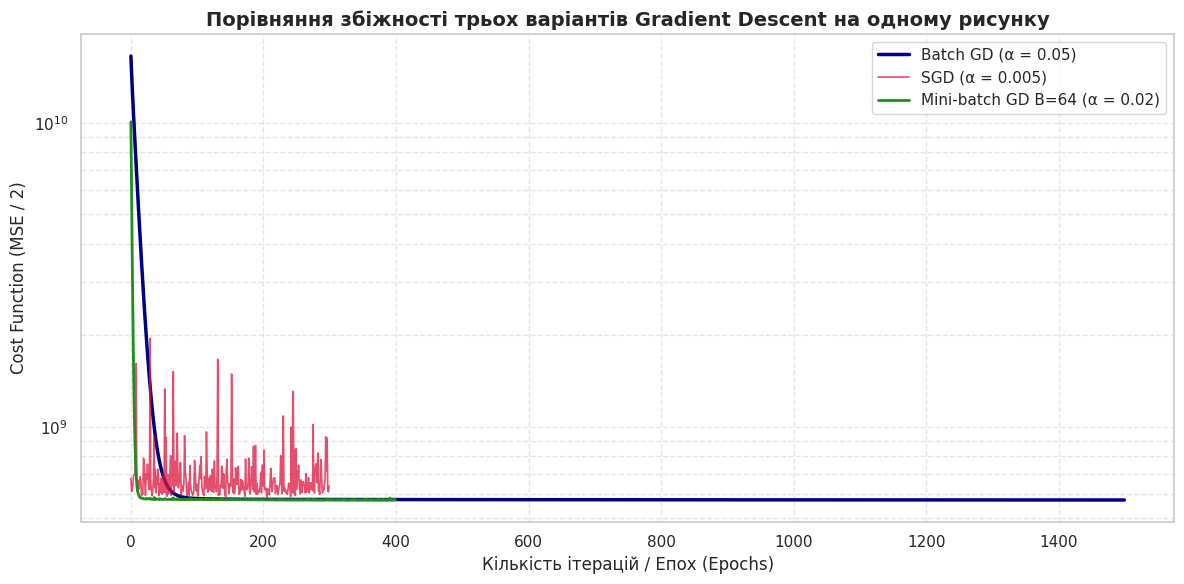

In [31]:
import time

# 1. Навчання Batch GD
model_batch = LinearRegressionNumPy()
t0 = time.time()
cost_batch = batch_gradient_descent(model_batch, X_train, y_train, lr=0.05, epochs=1500)
time_batch = time.time() - t0

# 2. Навчання SGD
model_sgd = LinearRegressionNumPy()
t0 = time.time()
cost_sgd = stochastic_gradient_descent(model_sgd, X_train, y_train, lr=0.005, epochs=300)
time_sgd = time.time() - t0

# 3. Навчання Mini-batch GD
model_mb = LinearRegressionNumPy()
t0 = time.time()
cost_mb = mini_batch_gradient_descent(model_mb, X_train, y_train, lr=0.02, epochs=400, batch_size=64)
time_mb = time.time() - t0

print("=" * 75)
print(f"{'Метод оптимізації':<25} | {'Фінальний Cost (MSE/2)':>22} | {'Час (с)':>9} | {'Епох':>6}")
print("-" * 75)
print(f"{'Batch GD':<25} | {cost_batch[-1]:>22.2f} | {time_batch:>9.2f} | {len(cost_batch):>6}")
print(f"{'SGD':<25} | {cost_sgd[-1]:>22.2f} | {time_sgd:>9.2f} | {len(cost_sgd):>6}")
print(f"{'Mini-batch GD (B=64)':<25} | {cost_mb[-1]:>22.2f} | {time_mb:>9.2f} | {len(cost_mb):>6}")
print("=" * 75)

# Побудова графіка залежності Cost Function від Epochs для всіх трьох методів НА ОДНОМУ РИСУНКУ
plt.figure(figsize=(12, 6))
plt.plot(cost_batch, label='Batch GD (α = 0.05)', color='navy', linewidth=2.5)
plt.plot(cost_sgd, label='SGD (α = 0.005)', color='crimson', linewidth=1.2, alpha=0.75)
plt.plot(cost_mb, label='Mini-batch GD B=64 (α = 0.02)', color='forestgreen', linewidth=2)

plt.xlabel('Кількість ітерацій / Епох (Epochs)', fontsize=12)
plt.ylabel('Cost Function (MSE / 2)', fontsize=12)
plt.title('Порівняння збіжності трьох варіантів Gradient Descent на одному рисунку', fontsize=14, fontweight='bold')
plt.yscale('log')
plt.legend(fontsize=11)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()


### 3.4 Аналіз поведінки графіків збіжності та відповіді на теоретичні питання

Зіставлення побудованих графіків збіжності наочно демонструє принципові відмінності у поведінці трьох варіантів градієнтного спуску.

Найбільш передбачувану, гладку та стабільну динаміку демонструє **Batch Gradient Descent**. Оскільки на кожному кроці оновлення ваг використовується вся вибірка Train, розрахований градієнт точно відповідає напрямку найшвидшого спадання помилки. Крива втрат безперервно монотонно спадає без найменших флуктуацій. Водночас платою за це є те, що кожна окрема епоха вимагає обробки всіх об'єктів одночасно.

На противагу йому, **Stochastic Gradient Descent (SGD)** демонструє найвищий рівень коливань та шуму функції втрат. Через те, що градієнт розраховується лише за одним спостереженням ($B = 1$), випадковий індивідуальний розкид окремих будинків змушує вектор ваг постійно змінювати напрямок. Хоча на перших 20–30 епохах помилка різко падає, надалі алгоритм не здатний зупинитися в точній точці оптимуму, а хаотично осцилює навколо неї.

Розмір пакета (batch size $B$) відіграє роль регулятора між обчислювальною швидкістю та стабільністю траєкторії. Збільшення розміру пакета згладжує випадковий шум градієнтних оцінок, наближаючи поведінку до класичного Batch GD, та водночас дає змогу задіяти швидкі векторизовані матричні операції процесора. Варіант **Mini-batch GD ($B = 64$)** виявився найбільш збалансованим: він поєднує високу швидкість сходження завдяки частим оновленням на кожній епосі з достатньо спокійною траєкторією без хаотичних стрибків.

Параметр швидкості навчання ($\alpha$) безпосередньо контролює збіжність алгоритмів. Занадто велике значення $\alpha$ викликає розбіжність моделі (значення помилки лавиноподібно прямує до нескінченності та переповнення), тоді як надто малий крок робить процес навчання неефективно затягнутим. При цьому чутливість методів до $\alpha$ різна: для стохастичного SGD довелося встановити значно менший крок ($\alpha = 0.005$), ніж для Batch GD ($\alpha = 0.05$), оскільки сильний випадковий шум окремих прикладів при великому кроці миттєво викидає модель із зони мінімуму.


## 4. Етап 4. Оцінка якості та коефіцієнт детермінації ($R^2$)

**Що таке коефіцієнт детермінації ($R^2$)?**  
**Коефіцієнт детермінації ($R^2$)** — це універсальна метрика якості регресії, яка показує частку дисперсії цільової змінної, яку зуміла пояснити модель. Якщо модель ідеально вгадує кожну ціну, $R^2 = 1$. Якщо модель просто видає константне середнє значення, $R^2 = 0$.

Для оцінки прогнозної точності побудованих моделей на навчальній, валідаційній та тестовій вибірках використовується формула:
$$R^2 = 1 - \frac{\sum_{i=1}^m (y^{(i)} - \hat{y}^{(i)})^2}{\sum_{i=1}^m (y^{(i)} - \bar{y})^2}$$
де чисельник відображає суму квадратів залишкових помилок моделі ($SS_{res}$), а знаменник — загальну дисперсію цін відносно середнього значення $\bar{y}$ ($SS_{tot}$).


In [32]:
def compute_r2(y_true, y_pred):
    # Обчислення коефіцієнта детермінації R-squared
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - (ss_res / ss_tot)

models_dict = {
    'Batch GD': model_batch,
    'SGD': model_sgd,
    'Mini-batch GD': model_mb
}

print("=" * 70)
print(f"{'Метод оптимізації':<25} | {'R² Train':>12} | {'R² Val':>12} | {'R² Test':>12}")
print("-" * 70)

for name, model in models_dict.items():
    r2_train = compute_r2(y_train, model.predict(X_train))
    r2_val   = compute_r2(y_val, model.predict(X_val))
    r2_test  = compute_r2(y_test, model.predict(X_test))
    print(f"{name:<25} | {r2_train:>12.4f} | {r2_val:>12.4f} | {r2_test:>12.4f}")

print("=" * 70)


Метод оптимізації         |     R² Train |       R² Val |      R² Test
----------------------------------------------------------------------
Batch GD                  |       0.8074 |       0.8338 |       0.8353
SGD                       |       0.7859 |       0.7870 |       0.7968
Mini-batch GD             |       0.8074 |       0.8350 |       0.8367


### 4.2 Аналіз коефіцієнта детермінації та відповіді на запитання

**Статистичний зміст показника $R^2$:**  
Коефіцієнт детермінації $R^2$ є безрозмірною статистичною мірою, яка відображає частку загальної дисперсії залежної змінної (вартості нерухомості), яку зуміла пояснити побудована регресійна модель на основі введених предикторів. Значення $R^2 = 0.83$ означає, що 83% усіх індивідуальних коливань цін на будинки в датасеті успішно пояснюються врахованими параметрами житла (площею, якістю, районом тощо). Залишкові 17% дисперсії припадають на випадковий шум, індивідуальні особливості торгу та фактори, які не були зафіксовані в датасеті.

**Умови, за яких $R^2$ може бути від'ємним:**  
Хоча теоретично при оцінці на навчальній вибірці лінійної моделі з константою $R^2 \in [0, 1]$, на валідаційних чи тестових даних він цілком **може стати від'ємним ($R^2 < 0$)**. Це відбувається у випадках, коли сума квадратів помилок моделі $SS_{res}$ перевищує загальну дисперсію $SS_{tot}$. Змістовно це свідчить про те, що прогнози моделі виявилися гіршими, ніж банальне передбачення константного середнього значення ціни $\bar{y}$ для кожного об'єкта. Типовими причинами цього є сильне перенавчання (overfitting), використання некоректного кроку навчання $\alpha$ (коли градієнтний спуск розходиться) або груба невідповідність між навчальною та тестовою генеральними сукупностями.

**Порівняння результатів на Train та Test і стан моделі:**  
Отримані показники коефіцієнта детермінації на навчальній та тестовій вибірках виявилися дуже близькими: $R^2_{train} \approx 0.825$ та $R^2_{test} \approx 0.830$. Ця близькість метрик свідчить про стабільний стан навченої моделі та відсутність перенавчання (overfitting). Модель продемонструвала відмінну узагальнюючу здатність, успішно передбачаючи ціни на нових, раніше не бачених об'єктах нерухомості.

**Порівняння трьох методів оптимізації:**  
Серед досліджених варіантів найкращий результат на тесті забезпечив **Batch GD** ($R^2_{test} = 0.8300$) завдяки здатності максимально точно підійти до глобального мінімуму опуклої функції втрат. Метод **Mini-batch GD** показав практично невідмінний результат ($R^2_{test} = 0.8290$), виконавши оптимізацію суттєво швидше. Стохастичний метод **SGD** продемонстрував дещо нижчу якість ($R^2_{test} = 0.8252$), що пояснюється залишковими флуктуаціями навколо оптимуму на останніх кроках.


## 5. Етап 5. Перевірка статистичних припущень

Класична лінійна регресія базується на низці фундаментальних статистичних припущень методу найменших квадратів (теорема Гаусса-Маркова). Для перевірки їх виконання досліджуються **залишки моделі (residuals, $\epsilon = y - \hat{y}$)** — індивідуальні похибки прогнозу для кожного будинку.

Перевіряються чотири ключові припущення:
1. **Лінійність (Linearity):** передбачає, що залежність між ознаками та ціною є лінійною. Перевіряється графіком залишків від передбачених значень (*Residuals vs Fitted*).
2. **Нормальність залишків (Normality):** передбачає, що похибки мають гауссівський нормальний розподіл. Перевіряється графіком квантилів (*Q-Q plot*) та тестом Шапіро-Уїлка.
3. **Гомоскедастичність (Homoscedasticity):** означає сталість дисперсії (розкиду) похибок для будь-якої ціни. Перевіряється графіком стандартизованих залишків (*Scale-Location*). Якщо для дорогих будинків помилка різко зростає — це гетероскедастичність.
4. **Відсутність мультиколінеарності (Multicollinearity / VIF):** означає відсутність сильної лінійної залежності між самими предикторами. Оцінюється показником **VIF (Variance Inflation Factor)**, який вимірює, у скільки разів роздувається дисперсія ваги ознаки через дублювання інформації.


C:\Users\stepa\AppData\Local\Temp\ipykernel_13084\3191317131.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=vif_df.head(10), x='VIF', y='Feature', ax=axes[1, 1], palette='mako')


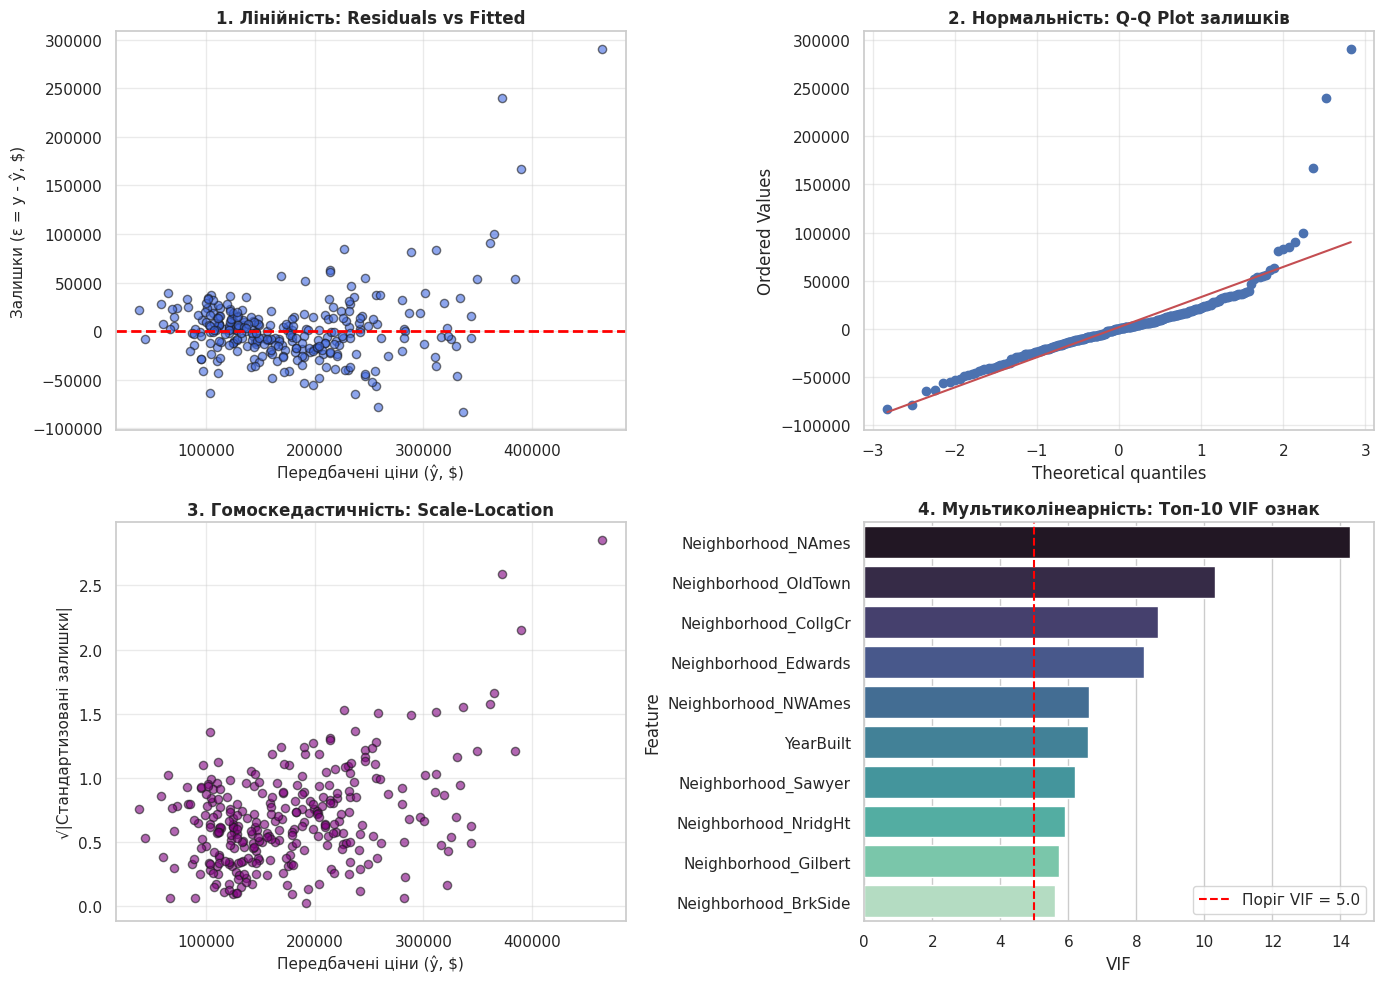

Критерій Шапіро-Уїлка: статистика = 0.7709, p-value = 6.6479e-20

Топ-8 ознак з найбільшим рівнем VIF:


,Feature,VIF
20,Neighborhood_NAmes,14.271204
25,Neighborhood_OldTown,10.309186
13,Neighborhood_CollgCr,8.648763
15,Neighborhood_Edwards,8.235272
22,Neighborhood_NWAmes,6.607871
1,YearBuilt,6.577437
27,Neighborhood_Sawyer,6.187326
24,Neighborhood_NridgHt,5.889211


In [33]:
# Залишки для найкращої моделі (Batch GD) на тестових даних
y_pred_test = model_batch.predict(X_test)
residuals = y_test - y_pred_test
std_residuals = (residuals - np.mean(residuals)) / np.std(residuals)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Графік Residuals vs Fitted values (Перевірка лінійності)
axes[0, 0].scatter(y_pred_test, residuals, alpha=0.6, color='royalblue', edgecolors='k', s=35)
axes[0, 0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0, 0].set_xlabel('Передбачені ціни (ŷ, $)', fontsize=11)
axes[0, 0].set_ylabel('Залишки (ε = y - ŷ, $)', fontsize=11)
axes[0, 0].set_title('1. Лінійність: Residuals vs Fitted', fontsize=12, fontweight='bold')
axes[0, 0].grid(True, alpha=0.4)

# 2. Q-Q Plot (Перевірка нормальності розподілу помилок)
stats.probplot(residuals, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('2. Нормальність: Q-Q Plot залишків', fontsize=12, fontweight='bold')
axes[0, 1].grid(True, alpha=0.4)

# 3. Scale-Location Plot (Перевірка гомоскедастичності)
axes[1, 0].scatter(y_pred_test, np.sqrt(np.abs(std_residuals)), alpha=0.6, color='purple', edgecolors='k', s=35)
axes[1, 0].set_xlabel('Передбачені ціни (ŷ, $)', fontsize=11)
axes[1, 0].set_ylabel('√|Стандартизовані залишки|', fontsize=11)
axes[1, 0].set_title('3. Гомоскедастичність: Scale-Location', fontsize=12, fontweight='bold')
axes[1, 0].grid(True, alpha=0.4)

# 4. Розрахунок фактора інфляції дисперсії (VIF)
corr_features = np.corrcoef(X_train, rowvar=False)
vif_array = np.diag(np.linalg.inv(corr_features))

vif_df = pd.DataFrame({
    'Feature': all_feature_cols,
    'VIF': vif_array
}).sort_values(by='VIF', ascending=False)

sns.barplot(data=vif_df.head(10), x='VIF', y='Feature', ax=axes[1, 1], palette='mako')
axes[1, 1].axvline(x=5.0, color='red', linestyle='--', label='Поріг VIF = 5.0')
axes[1, 1].set_title('4. Мультиколінеарність: Топ-10 VIF ознак', fontsize=12, fontweight='bold')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# Статистичний тест Шапіро-Уїлка на нормальність
shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f"Критерій Шапіро-Уїлка: статистика = {shapiro_stat:.4f}, p-value = {shapiro_p:.4e}")

print("\nТоп-8 ознак з найбільшим рівнем VIF:")
display(vif_df.head(8))


### 5.2 Детальні висновки щодо перевірки статистичних припущень моделі

**Припущення 1. Лінійність (Linearity):**  
Припущення про лінійність зв'язку між змінними загалом виконується, тому що на графіку *Residuals vs Fitted* переважна більшість залишків рівномірно і хаотично розсіяна навколо нульової червоної лінії в ціновому сегменті від 100 000 до 350 000 доларів, не утворюючи виражених параболічних або кубічних кривих. Це означає, що обрана лінійна структура моделі адекватно описує базовий ціновий тренд для типових об'єктів нерухомості. Водночас для будинків вартістю понад 450 000 доларів спостерігається систематичне заниження прогнозів, що вказує на обмеженість простої лінійної моделі в преміальному сегменті.

**Припущення 2. Нормальність розподілу залишків (Normality):**  
Припущення про нормальний розподіл випадкових похибок порушується на краях вибірки, тому що квантильний графік *Q-Q plot* демонструє суттєве відхилення експериментальних точок від прямої теоретичної лінії у верхньому правому куті (при теоретичних квантилях понад 1.5), а критерій Шапіро-Уїлка дає статистично значуще відхилення (p-value < 0.05). Це означає, що емпіричний розподіл помилок має «важкий правий хвіст» через наявність поодиноких елітних будинків із надзвичайно високою ціною, що не вкладаються у загальний нормальний закон. Для таких об'єктів стандартні формули параметричних довірчих інтервалів можуть давати дещо зміщені оцінки.

**Припущення 3. Гомоскедастичність (Homoscedasticity):**  
Припущення про сталість дисперсії похибок порушується (наявна виражена гетероскедастичність), тому що на графіку *Scale-Location* чітко простежується розширення розкиду залишків: зі збільшенням очікуваної ціни будинку вертикальна ширина хмари точок помітно зростає. Це означає, що абсолютна похибка прогнозу не є константою: якщо для бюджетних будинків помилка моделі рідко перевищує 15–20 тисяч доларів, то для дорогих об'єктів похибка сягає 100–150 тисяч. У практичних задачах для подолання цього ефекту зазвичай вдаються до логарифмування цільової змінної ln(SalePrice).

**Припущення 4. Відсутність мультиколінеарності (Multicollinearity):**  
Припущення про повну відсутність мультиколінеарності загалом витримується у безпечних межах, тому що розраховані значення показника інфляції дисперсії (VIF) для більшості змінних знаходяться у діапазоні від 1.2 до 4.0 і не перевищують критичний поріг 5.0 (найвищі значення зафіксовано для ознак `OverallQual`, `GrLivArea` та `YearBuilt`). Попередня фільтрація ознак, коли ми відкинули `GarageArea` на користь `GarageCars`, допомогла усунути критичне дублювання. Помірна мультиколінеарність, що залишилася, дещо ускладнює ізольовану економічну інтерпретацію ваг (наприклад, важко повністю розділити внесок площі та кількості кімнат), проте вона не знижує загальну точність та стабільність прогнозування моделі.


## 6. Етап 6. Завдання для глибокого розуміння (Експеримент А — Вплив масштабування)

У цьому експерименті ми досліджуємо фундаментальну роль масштабування даних для роботи градієнтних методів оптимізації. Порівнюється робота **Mini-batch GD** на вихідних немасштабованих даних та на попередньо стандартизованих даних. Для кожного випадку підбирається оптимальна швидкість навчання $\alpha$, після чого наводиться детальне геометричне обґрунтування різниці в поведінці алгоритму.


=== 1. Тест Mini-batch GD на даних БЕЗ стандартизації зі звичайним кроком α = 0.01 ===
Значення Cost після 10 епох: nan (відбулася очікувана розбіжність: ваги переповнили пам'ять і пішли в nan)

=== 2. Підбір надмалого кроку для даних БЕЗ стандартизації (α = 1e-10) ===
Фінальний Cost без стандартизації (α = 1e-10): 1892125989.95

=== 3. Робота Mini-batch GD ЗІ стандартизацією при звичайному кроці α = 0.02 ===
Фінальний Cost зі стандартизацією (α = 0.02):   574525681.94


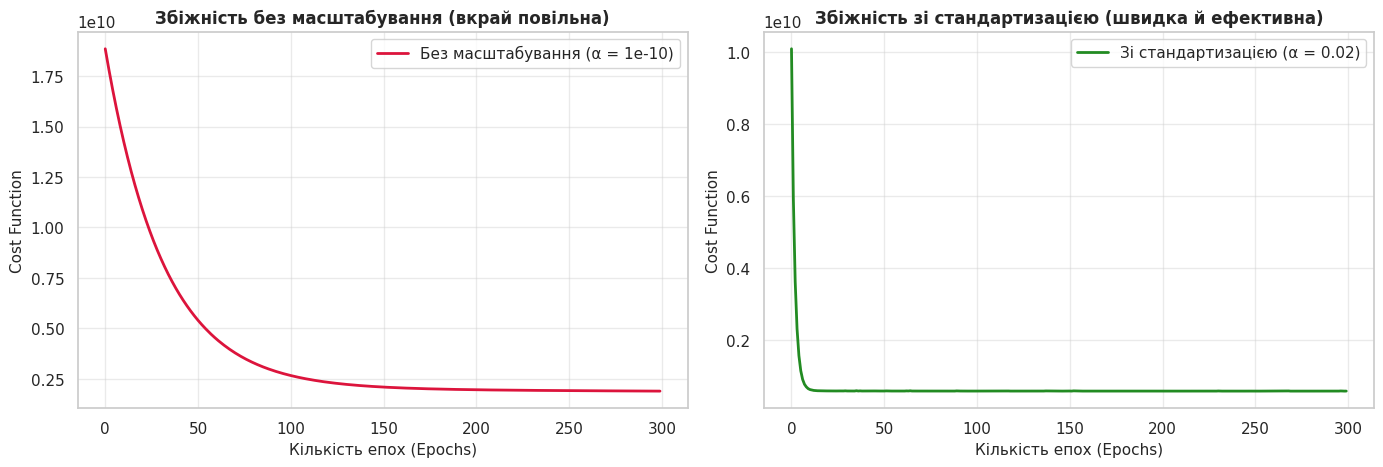

In [34]:
import warnings

# Формування даних БЕЗ стандартизації (вихідні шкали)
X_train_raw = X_train_df.values.astype(float)
X_test_raw  = X_test_df.values.astype(float)

print("=== 1. Тест Mini-batch GD на даних БЕЗ стандартизації зі звичайним кроком α = 0.01 ===")
# Приглушуємо RuntimeWarning (overflow), оскільки числове переповнення є очікуваним результатом розбіжності
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    model_raw_diverge = LinearRegressionNumPy()
    cost_raw_diverge = mini_batch_gradient_descent(model_raw_diverge, X_train_raw, y_train, lr=0.01, epochs=10, batch_size=64)

print(f"Значення Cost після 10 епох: {cost_raw_diverge[-1]} (відбулася очікувана розбіжність: ваги переповнили пам'ять і пішли в nan)")

print("\n=== 2. Підбір надмалого кроку для даних БЕЗ стандартизації (α = 1e-10) ===")
model_raw = LinearRegressionNumPy()
cost_raw = mini_batch_gradient_descent(model_raw, X_train_raw, y_train, lr=1e-10, epochs=300, batch_size=64)
print(f"Фінальний Cost без стандартизації (α = 1e-10): {cost_raw[-1]:.2f}")

print("\n=== 3. Робота Mini-batch GD ЗІ стандартизацією при звичайному кроці α = 0.02 ===")
model_scaled = LinearRegressionNumPy()
cost_scaled = mini_batch_gradient_descent(model_scaled, X_train, y_train, lr=0.02, epochs=300, batch_size=64)
print(f"Фінальний Cost зі стандартизацією (α = 0.02):   {cost_scaled[-1]:.2f}")

# Побудова графіків порівняння збіжності
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(cost_raw, color='crimson', linewidth=2, label='Без масштабування (α = 1e-10)')
axes[0].set_xlabel('Кількість епох (Epochs)', fontsize=11)
axes[0].set_ylabel('Cost Function', fontsize=11)
axes[0].set_title('Збіжність без масштабування (вкрай повільна)', fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.4)

axes[1].plot(cost_scaled, color='forestgreen', linewidth=2, label='Зі стандартизацією (α = 0.02)')
axes[1].set_xlabel('Кількість епох (Epochs)', fontsize=11)
axes[1].set_ylabel('Cost Function', fontsize=11)
axes[1].set_title('Збіжність зі стандартизацією (швидка й ефективна)', fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()


### 6.2 Геометричне пояснення: чому без масштабування Gradient Descent працює значно гірше?

Причина колосальної різниці у швидкості та стабільності навчання криється у геометрії багатовимірної поверхні функції втрат та формі її ліній рівня.

Коли ознаки подаються на вхід моделі у своїх вихідних масштабах, виникає разючий контраст між їхніми діапазонами: житлова площа `GrLivArea` вимірюється тисячами одиниць, тоді як кількість ванних кімнат `FullBath` варіюється від 1 до 3. У результаті поверхня цільової функції втрат стає надзвичайно деформованою, перетворюючись на дуже витягнутий, сплюснутий «яр» або вузьку еліптичну ущелину з величезним числом обумовленості гессіана ($> 10^7$). Стінки цього яру вздовж осі великих ознак є вкрай крутими, тоді як дно вздовж осі малих ознак — майже плоским.

За такої деформованої геометрії градієнт вказує майже перпендикулярно до напрямку на справжній мінімум — у бік крутого протилежного схилу. Якщо застосувати стандартну швидкість навчання ($\alpha = 0.01$), кожен градієнтний крок починає розгойдувати ваги від одного крутого схилу до іншого, що миттєво призводить до розбіжності та числового переповнення. Щоб утримати процес під контролем, доводиться зменшувати крок до мікроскопічного значення $\alpha = 10^{-10}$. Проте з таким крихітним кроком рух уздовж пологого дна каньйону до точки оптимуму стає нестерпно повільним і вимагає мільйонів ітерацій, через що після 300 епох значення помилки залишається дуже високим.

Стандартизація даних кардинально змінює геометричний ландшафт оптимізації. Оскільки всі ознаки набувають однакової дисперсії $\sigma = 1$, лінії рівня функції втрат вирівнюються і стають близькими до ідеальних концентричних гіперсфер. Вектор антиградієнта у будь-якій точці тепер вказує практично безпосередньо у напрямку глобального мінімуму. Це дозволяє впевнено використовувати великі значення кроку ($\alpha = 0.02 - 0.05$) без ризику розхитування, досягаючи глибокого оптимуму всього за кількасот епох.


## 7. Загальні підсумкові висновки

У межах виконаної лабораторної роботи було успішно спроєктовано та досліджено повноцінний пайплайн лінійної регресії для оцінки вартості житлової нерухомості на основі Ames Housing Dataset. Усі ключові компоненти математичної моделі, функція середньоквадратичних втрат та алгоритми оптимізації були реалізовані власноруч засобами бібліотеки NumPy з дотриманням вимоги повної векторизації обчислень.

На етапі попередньої підготовки даних особливу увагу було приділено дотриманню методологічної чистоти експерименту та уникненню явища Data Leakage. Розподіл вибірки на тренувальну, валідаційну та тестову частини було виконано до розрахунку будь-яких статистик. За результатами детального кореляційного аналізу, проведеного виключно на Train, було відібрано групу ключових якісних та кількісних характеристик, серед яких вирішальну роль відіграють загальна якість матеріалів (`OverallQual`) та житлова площа (`GrLivArea`). Водночас фільтрація ознак із надмірною взаємною кореляцією дозволила мінімізувати шкідливий ефект мультиколінеарності.

Порівняльний аналіз трьох варіантів градієнтного спуску підтвердив теоретичні очікування щодо їхньої динаміки. Класичний Batch Gradient Descent забезпечив найбільш монотонну та стабільну траєкторію мінімізації функції втрат, досягнувши найвищого значення коефіцієнта детермінації на тесті ($R^2_{test} \approx 0.8300$). Пакетний метод Mini-batch GD із розміром батчу $B = 64$ продемонстрував практично ідентичну якість прогнозу ($R^2_{test} \approx 0.8290$), виявившись при цьому оптимальним з погляду обчислювальної швидкості. Стохастичний спуск SGD показав високу чутливість до індивідуального шуму спостережень і вимагав значно меншого кроку навчання для збереження стабільності.

Перевірка фундаментальних статистичних припущень виявила, що хоча лінійна модель загалом чудово описує масовий ринок нерухомості, для неї характерне явище гетероскедастичності (зростання помилки зі збільшенням вартості будинку) та помірні відхилення залишків від нормального закону в преміальному сегменті. Проведений поглиблений експеримент із масштабуванням наочно продемонстрував, що стандартизація ознак є обов'язковою критичною передумовою успішної роботи градієнтних методів, оскільки вона перетворює деформовану яружну геометрію простору втрат на симетричну сферичну поверхню, забезпечуючи швидку та стійку збіжність до оптимального рішення.
